# moonshot_ml_sandbox — Phase 3b: do the models beat a simple sort?

**Question (pre-registered).** Phase 3a found that three model portfolios improved the Sharpe
ratio, and the diagnostic showed they lean on two well-known traits: **low volatility** and
**momentum**. Does the fitted model add anything beyond a hand-made sort on those traits?

**The twins** use the *same* z-scores on the *same* 141 months, with no fitting:

| Model portfolio (Phase 3a) | No-model twin | Rule |
|---|---|---|
| Avoid crashes | **Twin: cut most volatile** | hold all except the 20% with highest `realized_vol_60_z` |
| Avoid wild movers | **Twin: cut most volatile** (same twin) | as above |
| Pick outperformers | **Twin: momentum − volatility** | hold the 20% with highest `momentum_12_1_z − realized_vol_60_z` |
| *(reference only)* | **Ref: momentum only** | hold the 20% with highest `momentum_12_1_z` |

**Pre-committed reading rule (3 primary pairs).** Paired block bootstrap of *model minus twin*
(6-month blocks, 2,000 draws). On the Sharpe difference:
- CI entirely above 0 → **model adds value** beyond the sort
- CI entirely below 0 → **twin is better**
- CI includes 0 → **no detectable difference** (the model adds nothing we can measure beyond the sort)

Primary CI is 95%; the 98.33% CI (three pairs tested at once) is shown alongside.
Active return, volatility, drawdown, turnover and the month-by-month **overlap** of holdings
are reported but do not decide the verdict.

**Expectations (written before the run).** Avoid portfolios vs their twin: high overlap,
no detectable difference. Pick outperformers vs its twin: probably no detectable difference,
though the model also leans on overnight drift (−0.39) and turnover (+0.19), so its holdings
may differ more.

**Honest caveat about the twins.** The momentum − volatility twin was designed *after* seeing
the model's full-period tilts, which is hindsight that favours the twin. Both traits are
long-known factors, so the twin is plausible without that hindsight, but a tie should be read
as "the model is mostly these two factors", not as proof the model is useless.

**Cells 0–7 are copied unchanged from Phase 3a v2** (they rebuild the same predictions,
gap handling and snapshots). Cell 8 checks this reproduces Phase 3a's numbers before anything new runs.

## Cell 0 — Mount and locate inputs (read-only)

In [2]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')
SANDBOX_DIR = Path("/content/drive/MyDrive/moonshot_ml_sandbox")
DATASET_PATH = sorted(SANDBOX_DIR.glob("ml_sandbox_v1_dataset_*.parquet"))[-1]
PANEL_PATH = sorted(Path("/content/drive/MyDrive/moonshot_compounding/features")
                    .glob("feature_panel_with_pit_v2_*.parquet"))[-1]
print("V1 dataset  :", DATASET_PATH.name, "\nsource panel:", PANEL_PATH.name)

Mounted at /content/drive
V1 dataset  : ml_sandbox_v1_dataset_2026-09-07.parquet 
source panel: feature_panel_with_pit_v2_2026-07-24.parquet


## Cell 1 — Logistic engine (identical to Phase 2, self-tested)

In [3]:
# ==============================================================================
# LOGISTIC-REGRESSION ENGINE  (identical code is self-tested on synthetic data)
# ==============================================================================
import warnings
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

EPS = 1e-12
RUNGS = ["M0", "M1", "M2"]          # M0 intercept only | M1 linear | M2 linear + squares


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def make_folds(dates, train_years=3, purge=21, max_test_year=None):
    # Rolling folds: train on `train_years` calendar years, test on the next one.
    # PURGE: drop the last `purge` trading dates before the train cutoff, so no
    # training card's 21-day forward window reaches into the test year.
    all_dates = np.array(sorted(pd.unique(dates)))
    first_year = pd.Timestamp(all_dates[0]).year
    last_date = pd.Timestamp(all_dates[-1])
    folds = []
    y0 = first_year
    while True:
        tr_lo = pd.Timestamp(f"{y0}-01-01")
        tr_hi = pd.Timestamp(f"{y0 + train_years - 1}-12-31")
        te_lo = pd.Timestamp(f"{y0 + train_years}-01-01")
        te_hi = pd.Timestamp(f"{y0 + train_years}-12-31")
        if te_lo > last_date or (max_test_year is not None and y0 + train_years > max_test_year):
            break
        hi_pos = np.searchsorted(all_dates, np.datetime64(tr_hi), side="right") - 1
        purge_from = pd.Timestamp(all_dates[hi_pos - purge + 1])
        folds.append(dict(test_year=y0 + train_years, train_lo=tr_lo,
                          purge_from=purge_from, train_hi=tr_hi,
                          test_lo=te_lo, test_hi=te_hi))
        y0 += 1
    return folds


def split_fold(frame, f):
    tr = frame[(frame["date"] >= f["train_lo"]) & (frame["date"] < f["purge_from"])]
    te = frame[(frame["date"] >= f["test_lo"]) & (frame["date"] <= f["test_hi"])]
    return tr, te


def design(frame, rung, feats):
    # M0: no features. M1: the z-scored features. M2: features + their squares.
    if rung == "M0":
        return np.zeros((len(frame), 0))
    X = frame[feats].to_numpy(dtype=float)
    if rung == "M2":
        X = np.column_stack([X, X ** 2])
    return X


def fit_logit(X, y):
    # Unregularized maximum-likelihood logistic regression.
    # Returns intercept b, weights w, and whether the optimizer converged.
    y = np.asarray(y, dtype=float)
    if X.shape[1] == 0:
        p = y.mean()
        return dict(b=float(np.log(p / (1 - p))), w=np.zeros(0), converged=True)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            m = LogisticRegression(penalty=None, solver="lbfgs", max_iter=5000)
            m.fit(X, y)
        except (ValueError, TypeError):   # older sklearn: no penalty=None
            m = LogisticRegression(C=1e10, solver="lbfgs", max_iter=5000)
            m.fit(X, y)
    conv = not any("converge" in str(c.message).lower() for c in caught)
    return dict(b=float(m.intercept_[0]), w=m.coef_[0].copy(), converged=conv)


def predict(model, X):
    return sigmoid(model["b"] + X @ model["w"])


def gradient_descent_logit(X, y, lr=2.0, n_iter=1500):
    # From-scratch fit: w <- w - lr * X^T (p - y) / n  (intercept as a column of 1s)
    Xa = np.column_stack([np.ones(len(X)), X])
    w = np.zeros(Xa.shape[1])
    hist = []
    for _ in range(n_iter):
        p = sigmoid(Xa @ w)
        hist.append(-np.mean(y * np.log(np.clip(p, EPS, 1)) +
                             (1 - y) * np.log(np.clip(1 - p, EPS, 1))))
        w -= lr * Xa.T @ (p - y) / len(y)
    return w, np.array(hist)


def logloss_vec(y, p):
    p = np.clip(p, EPS, 1 - EPS)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))


def daily_table(dates, y, preds):
    # Per-date sums of log-loss for each rung, and per-date AUC (rank formula).
    # AUC for one date = P(a random event stock outranks a random non-event stock).
    d = pd.DataFrame({"date": dates, "y": y})
    out = {}
    g = d.groupby("date")["y"]
    n = g.size()
    n1 = g.sum()
    n0 = n - n1
    out["n"] = n
    for r, p in preds.items():
        d["ll"] = logloss_vec(d["y"].to_numpy(), p)
        out[f"ll_{r}"] = d.groupby("date")["ll"].sum()
        d["rk"] = pd.Series(p, index=d.index).groupby(d["date"]).rank(method="average")
        sr = d.loc[d["y"] == 1].groupby("date")["rk"].sum().reindex(n.index).fillna(0.0)
        auc = (sr - n1 * (n1 + 1) / 2) / (n1 * n0)
        auc[(n1 == 0) | (n0 == 0)] = np.nan
        out[f"auc_{r}"] = auc
    return pd.DataFrame(out)


def summarize(daily, rung):
    skill = 1 - daily[f"ll_{rung}"].sum() / daily["ll_M0"].sum()
    return skill, daily[f"auc_{rung}"].mean()


def block_bootstrap(daily, B=1000, seed=0):
    # Resample whole calendar MONTHS with replacement (preserves within-month
    # dependence). Returns bootstrap draws of skill/AUC for M1, M2 and the
    # paired M2-minus-M1 skill gain.
    rng = np.random.default_rng(seed)
    month = daily.index.to_period("M")
    agg = pd.DataFrame({
        "ll0": daily["ll_M0"], "ll1": daily["ll_M1"], "ll2": daily["ll_M2"],
        "a1": daily["auc_M1"].fillna(0), "a2": daily["auc_M2"].fillna(0),
        "na": daily["auc_M1"].notna().astype(float),
    }).groupby(month).sum()
    A = agg.to_numpy()
    M = len(agg)
    idx = rng.integers(0, M, size=(B, M))
    C = np.zeros((B, M))
    for b in range(B):
        C[b] = np.bincount(idx[b], minlength=M)
    T = C @ A
    ll0, ll1, ll2, a1, a2, na = T.T
    s1, s2 = 1 - ll1 / ll0, 1 - ll2 / ll0
    return dict(skill_M1=s1, skill_M2=s2, gain=s2 - s1, auc_M1=a1 / na, auc_M2=a2 / na)


def calibration_bins(y, p, n_bins=10):
    b = pd.qcut(pd.Series(p), n_bins, labels=False, duplicates="drop")
    t = pd.DataFrame({"b": b.to_numpy(), "y": y, "p": p}).groupby("b")
    return t["p"].mean().to_numpy(), t["y"].mean().to_numpy(), t.size().to_numpy()


def run_event(frame, event_col, feats, folds, verbose=True):
    # Fit M0/M1/M2 on each fold's TRAIN, score on its TEST. Returns
    # pooled test predictions, per-date scores, per-fold weights, diagnostics.
    sub = frame[frame[event_col].notna()]
    rows, weights, diag = [], [], []
    for f in folds:
        tr, te = split_fold(sub, f)
        if len(tr) == 0 or len(te) == 0:
            continue
        ytr = tr[event_col].to_numpy(float)
        yte = te[event_col].to_numpy(float)
        pred = {}
        for r in RUNGS:
            m = fit_logit(design(tr, r, feats), ytr)
            pred[r] = predict(m, design(te, r, feats))
            weights.append(dict(test_year=f["test_year"], rung=r, b=m["b"],
                                **{f"w{i}": v for i, v in enumerate(m["w"])}))
            if r == "M0":
                diag.append(dict(test_year=f["test_year"], train_rate=ytr.mean(),
                                 test_rate=yte.mean(), b_M0=m["b"],
                                 logit_train_rate=np.log(ytr.mean() / (1 - ytr.mean()))))
            if not m["converged"]:
                print(f"  WARNING: {event_col} {r} fold {f['test_year']} did not converge")
        rows.append(pd.DataFrame({"date": te["date"].to_numpy(),
                                  "ticker": te["ticker"].to_numpy(),
                                  "test_year": f["test_year"], "y": yte,
                                  "p_M0": pred["M0"], "p_M1": pred["M1"], "p_M2": pred["M2"]}))
        if verbose:
            print(f"  {event_col}: fold {f['test_year']} fitted "
                  f"(train {len(tr):,} / test {len(te):,})")
    preds = pd.concat(rows, ignore_index=True)
    daily = daily_table(preds["date"].to_numpy(), preds["y"].to_numpy(),
                        {r: preds[f"p_{r}"].to_numpy() for r in RUNGS})
    daily["test_year"] = pd.Series(pd.to_datetime(daily.index).year, index=daily.index)
    return dict(preds=preds, daily=daily, weights=pd.DataFrame(weights),
                diag=pd.DataFrame(diag))

## Cell 2 — Portfolio engine (self-tested, including the gap-handling calendar)

In [4]:
# ==============================================================================
# PORTFOLIO ENGINE  (identical code is self-tested on synthetic data)
# ==============================================================================
import numpy as np
import pandas as pd

ANN = 12   # monthly rebalancing -> 12 periods per year

# Each portfolio: (prediction column, "top" = hold highest 20%, "drop" = hold all
# except highest 20%).  None = baseline (hold everything).
PORTFOLIOS = {
    "Baseline":           None,
    "Pick outperformers": ("p_outperform", "top"),
    "Pick big winners":   ("p_top", "top"),
    "Avoid crashes":      ("p_crash", "drop"),
    "Avoid wild movers":  ("p_highvol", "drop"),
}


def rebalance_dates(dates):
    # First available date of each calendar month (kept for reference; the
    # notebook uses plan_rebalances, which also checks for data gaps).
    s = pd.Series(pd.to_datetime(pd.unique(dates))).sort_values()
    return s.groupby(s.dt.to_period("M")).min().to_numpy()


def trading_calendar(dates, flags, min_names=30):
    # The market's trading days, taken from the SOURCE PANEL (not from V1), so a
    # hole in V1 shows up as "trading day with no cards" instead of vanishing.
    # A date counts if at least `min_names` stocks are in the index on it.
    d = pd.DataFrame({"date": pd.to_datetime(dates),
                      "in_index": (np.asarray(flags, dtype=float) == 1)})
    n = d.groupby("date")["in_index"].sum()
    return pd.DatetimeIndex(n.index[n >= min_names]).sort_values()


def plan_rebalances(calendar, card_dates, start, end, max_delay=3):
    # One row per calendar month in [start, end].
    #   first_trading_day : first trading day of the month (from the calendar)
    #   rebalance_date    : first trading day of the month that HAS cards
    #   delay             : trading days between the two (0 = normal)
    #   invest            : True if cards exist and delay <= max_delay
    # A month whose cards start late is SKIPPED, never shifted: shifting would make
    # its 20-day holding overlap the next month's.
    cal = pd.DatetimeIndex(pd.to_datetime(calendar)).unique().sort_values()
    has_cards = cal.isin(pd.DatetimeIndex(pd.to_datetime(pd.unique(card_dates))))
    pos = np.arange(len(cal))
    month = cal.to_period("M")
    rows = []
    for m in pd.period_range(start, end, freq="M"):
        in_m = np.asarray(month == m)
        if not in_m.any():
            rows.append(dict(month=str(m), first_trading_day=pd.NaT, rebalance_date=pd.NaT,
                             delay=np.nan, invest=False, status="no trading days in calendar"))
            continue
        first_pos = pos[in_m][0]
        card_pos = pos[in_m & has_cards]
        if len(card_pos) == 0:
            rows.append(dict(month=str(m), first_trading_day=cal[first_pos], rebalance_date=pd.NaT,
                             delay=np.nan, invest=False, status="no cards this month -> sit out"))
            continue
        delay = int(card_pos[0] - first_pos)
        invest = delay <= max_delay
        status = "ok" if delay == 0 else f"cards start {delay} trading day(s) late"
        if not invest:
            status += f" (> {max_delay}) -> sit out"
        rows.append(dict(month=str(m), first_trading_day=cal[first_pos],
                         rebalance_date=cal[card_pos[0]] if invest else pd.NaT,
                         delay=delay, invest=invest, status=status))
    return pd.DataFrame(rows)


def holding_gaps(calendar, reb_dates, hold=20):
    # For consecutive rebalances t and t' (gap = trading days between them):
    # holding t runs open[t+1] -> open[t+1+hold]; the next starts at open[t'+1].
    #   overlap = days both are held = max(0, hold - gap)
    #   uncovered = days neither is held = max(0, gap - hold)
    # Pairs that are not consecutive calendar months (a sit-out in between) are
    # flagged and excluded from the overlap statistics.
    cal = pd.DatetimeIndex(pd.to_datetime(calendar)).unique().sort_values()
    reb = pd.DatetimeIndex(pd.to_datetime(reb_dates)).sort_values()
    p = cal.get_indexer(reb)
    if (p < 0).any():
        raise ValueError(f"rebalance dates not in calendar: {list(reb[p < 0])}")
    month_no = np.asarray(reb.year * 12 + reb.month)           # months since year 0
    out = pd.DataFrame({"from": reb[:-1], "to": reb[1:], "gap": np.diff(p),
                        "adjacent_months": np.diff(month_no) == 1})
    out["overlap"] = np.maximum(0, hold - out["gap"])
    out["uncovered"] = np.maximum(0, out["gap"] - hold)
    return out


def select(day, rule, frac=0.20):
    # Boolean mask of the stocks held on one rebalance date.
    if rule is None:
        return np.ones(len(day), dtype=bool)
    col, kind = rule
    n = len(day)
    k = int(round(frac * n))                       # exact count flagged
    order = day[col].rank(method="first").to_numpy()   # 1 = lowest prediction
    flagged = order > n - k                        # the k highest predictions
    return flagged if kind == "top" else ~flagged


def build(snap, portfolios=PORTFOLIOS, frac=0.20):
    # snap: one row per (rebalance date, stock) with 'ret' and prediction columns.
    # Returns monthly portfolio returns, holdings, and held/dropped diagnostics.
    rets, holds, diag = {p: {} for p in portfolios}, {p: {} for p in portfolios}, []
    for d, day in snap.groupby("date", sort=True):
        day = day.reset_index(drop=True)
        for p, rule in portfolios.items():
            m = select(day, rule, frac)
            rets[p][d] = day.loc[m, "ret"].mean()
            holds[p][d] = frozenset(day.loc[m, "ticker"])
            if rule is not None and "ev_crash" in day:
                diag.append(dict(date=d, portfolio=p, n_held=int(m.sum()),
                                 n_other=int((~m).sum()),
                                 ret_held=day.loc[m, "ret"].mean(),
                                 ret_other=day.loc[~m, "ret"].mean(),
                                 crash_held=day.loc[m, "ev_crash"].mean(),
                                 crash_other=day.loc[~m, "ev_crash"].mean()))
    R = pd.DataFrame(rets).sort_index()
    return R, holds, pd.DataFrame(diag)


def turnover(hold_by_date):
    # One-way turnover between consecutive equal-weight portfolios:
    # 0.5 * sum |w_t - w_{t-1}|.  0 = unchanged, 1 = completely replaced.
    ds = sorted(hold_by_date)
    out = []
    for a, b in zip(ds[:-1], ds[1:]):
        A, Bh = hold_by_date[a], hold_by_date[b]
        wa, wb = 1 / len(A), 1 / len(Bh)
        tot = sum(abs((wb if s in Bh else 0) - (wa if s in A else 0)) for s in A | Bh)
        out.append(0.5 * tot)
    return float(np.mean(out)) if out else np.nan


def wealth_curve(r):
    return np.concatenate([[1.0], np.cumprod(1 + np.asarray(r, float))])


def max_drawdown(r):
    w = wealth_curve(r)
    return float((w / np.maximum.accumulate(w) - 1).min())


def perf(r):
    r = np.asarray(r, float)
    n = len(r)
    return dict(cagr=wealth_curve(r)[-1] ** (ANN / n) - 1,
                vol=r.std(ddof=1) * np.sqrt(ANN),
                sharpe=r.mean() / r.std(ddof=1) * np.sqrt(ANN),
                max_dd=max_drawdown(r),
                hit_months=float(np.mean(r > 0)))


def block_indices(n, block, rng):
    # Indices for one moving-block bootstrap sample of length n.
    starts = rng.integers(0, n - block + 1, size=int(np.ceil(n / block)))
    return np.concatenate([np.arange(s, s + block) for s in starts])[:n]


def paired_bootstrap(rp, rb, B=2000, block=6, seed=0):
    # Resample the SAME months for portfolio and baseline (paired), in blocks of
    # `block` consecutive months to keep short-run dependence. Returns draws of:
    # annualised active return, volatility difference, Sharpe difference.
    rp, rb = np.asarray(rp, float), np.asarray(rb, float)
    rng = np.random.default_rng(seed)
    out = np.empty((B, 3))
    for b in range(B):
        i = block_indices(len(rp), block, rng)
        p, q = rp[i], rb[i]
        out[b] = [(p - q).mean() * ANN,
                  (p.std(ddof=1) - q.std(ddof=1)) * np.sqrt(ANN),
                  (p.mean() / p.std(ddof=1) - q.mean() / q.std(ddof=1)) * np.sqrt(ANN)]
    return dict(active=out[:, 0], vol_diff=out[:, 1], sharpe_diff=out[:, 2])

## Cell 3 — Rebuild the four events exactly as in Phase 2

In [5]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from datetime import date
df = pd.read_parquet(DATASET_PATH); df["date"] = pd.to_datetime(df["date"])
RAW = ["momentum_12_1","reversal_1m","realized_vol_60","log_turnover","overnight_drift"]
Z = [f + "_z" for f in RAW]
panel = pd.read_parquet(PANEL_PATH, columns=["Date","ticker","Open","Close","daily_return","in_nifty500_flag"])
panel["Date"] = pd.to_datetime(panel["Date"]).dt.tz_localize(None)
panel = panel.sort_values(["ticker","Date"]).reset_index(drop=True)
panel["fwd_vol"] = (panel.groupby("ticker")["daily_return"]
                    .transform(lambda s: s.rolling(20, min_periods=10).std().shift(-20)))
df = df.merge(panel[["Date","ticker","fwd_vol"]], left_on=["date","ticker"],
              right_on=["Date","ticker"], how="left").drop(columns=["Date"])
df = df.sort_values(["date","ticker"]).reset_index(drop=True)
pct = lambda c: df.groupby("date")[c].rank(pct=True)
r = pct("fwd_ret_20d")
df["ev_outperform"] = (r > 0.5).astype(float)
df["ev_top"] = (r > 0.8).astype(float)
df["ev_crash"] = (r <= 0.2).astype(float)
df["ev_highvol"] = np.where(df["fwd_vol"].notna(), (pct("fwd_vol") > 0.8).astype(float), np.nan)
EVENTS = ["ev_outperform","ev_top","ev_crash","ev_highvol"]
for e in EVENTS: print(f"  {e:<14} rate {df[e].mean():.4f}")

  ev_outperform  rate 0.5006
  ev_top         rate 0.2009
  ev_crash       rate 0.1993
  ev_highvol     rate 0.2009


## Cell 4 — Out-of-sample predictions (re-fitted, then checked against Phase 2)

Same engine, same data, same folds → the predictions must reproduce Phase 2's skill scores.
That check (below) is the proof that these are the same out-of-sample forecasts.
They are saved once to Drive so later phases can reuse them; if a saved file already exists it is loaded, never overwritten.

In [6]:
PRED_PATH = SANDBOX_DIR / f"phase2_oos_predictions_{date.today().isoformat()}.parquet"
existing = sorted(SANDBOX_DIR.glob("phase2_oos_predictions_*.parquet"))
folds = make_folds(df["date"], max_test_year=2025)
if existing:
    preds = pd.read_parquet(existing[-1]); print("loaded cached predictions:", existing[-1].name)
else:
    t0 = time.time(); parts = []
    for e in EVENTS:
        out = run_event(df, e, Z, folds, verbose=False)
        parts.append(out["preds"].assign(event=e)); print(f"  fitted {e}")
    preds = pd.concat(parts, ignore_index=True)
    assert not PRED_PATH.exists()
    preds.to_parquet(PRED_PATH, index=False)
    print(f"fitted and saved {PRED_PATH.name} in {(time.time()-t0)/60:.1f} min")
preds["date"] = pd.to_datetime(preds["date"])

# TRIPWIRE: reproduce Phase 2 skill (values from the Phase 2 run)
PHASE2 = {("ev_outperform","M1"):0.0027, ("ev_top","M1"):0.0022, ("ev_crash","M1"):0.0192,
          ("ev_highvol","M1"):0.1292, ("ev_highvol","M2"):0.1435}
print("\nreproduction check (skill vs Phase 2):")
for (e, rg), ref in PHASE2.items():
    p = preds[preds.event == e]
    dl = daily_table(p["date"].to_numpy(), p["y"].to_numpy(), {r: p[f"p_{r}"].to_numpy() for r in RUNGS})
    s = summarize(dl, rg)[0]
    print(f"  {e:<14} {rg}: {s:.4f}  (Phase 2: {ref:.4f})")
    assert abs(s - ref) < 6e-4, "predictions do not reproduce Phase 2 — stop"
print("[PASS] predictions reproduce Phase 2")

loaded cached predictions: phase2_oos_predictions_2026-10-03.parquet

reproduction check (skill vs Phase 2):
  ev_outperform  M1: 0.0027  (Phase 2: 0.0027)
  ev_top         M1: 0.0022  (Phase 2: 0.0022)
  ev_crash       M1: 0.0192  (Phase 2: 0.0192)
  ev_highvol     M1: 0.1292  (Phase 2: 0.1292)
  ev_highvol     M2: 0.1435  (Phase 2: 0.1435)
[PASS] predictions reproduce Phase 2


## Cell 5 — Data-gap audit: where is V1 missing days, and why?

**A.** Build the market's trading calendar from the *source panel* (days with ≥30 in-index
stocks). Every trading day inside V1's date span that has no V1 cards is listed, grouped
into runs of consecutive days. Short runs next to the vendor-failure date are expected
(a card whose buy or sell day is 2025-03-18 has no defined return). Exactly **one long run**
(≥5 days) is expected, containing 2025-03-18. Anything else stops the notebook.

**B.** Test the suspected cause. The V1 builder reads `realized_vol_60` straight from the
panel and drops any card with a missing feature. If the panel's 60-day volatility needs all
60 daily returns, one missing return on 2025-03-18 blanks it for ~60 trading days. Below:
the share of in-index stocks with a missing value, for each column the builder uses,
before / inside / after the hole. This part is diagnostic only. It does not change the
portfolios, and it never stops the run.

In [7]:
import pyarrow.parquet as pq
VENDOR_FAIL = pd.Timestamp("2025-03-18")

# ---- A. trading days with no V1 cards --------------------------------------
CAL = trading_calendar(panel["Date"], panel["in_nifty500_flag"], min_names=30)
v1_days = pd.DatetimeIndex(df["date"].unique()).sort_values()
print(f"market calendar (panel, >=30 in-index names): {len(CAL):,} trading days, "
      f"{CAL[0].date()} -> {CAL[-1].date()}")
print(f"V1 card dates                                : {len(v1_days):,} days, "
      f"{v1_days[0].date()} -> {v1_days[-1].date()}")
print(f"vendor-failure date {VENDOR_FAIL.date()} in market calendar: {VENDOR_FAIL in CAL}")
outside = v1_days.difference(CAL)
assert len(outside) == 0, f"V1 has card dates that are not market trading days: {list(outside[:5])}"
print("[PASS] every V1 card date is a market trading day")

span = CAL[(CAL >= v1_days[0]) & (CAL <= v1_days[-1])]
no_cards = span[~span.isin(v1_days)]
pos_nc = span.get_indexer(no_cards)
run_id = np.concatenate([[0], np.cumsum(np.diff(pos_nc) != 1)]) if len(pos_nc) else np.array([], int)
RUNS = (pd.DataFrame({"day": no_cards, "run": run_id}).groupby("run")["day"]
        .agg(first="min", last="max", trading_days="size").reset_index(drop=True))
# Days whose buy (t+1) or sell (t+21) open falls on the vendor date: return undefined by design.
if VENDOR_FAIL in CAL:
    vpos = CAL.get_loc(VENDOR_FAIL)
    by_design = {CAL[vpos - 1], CAL[vpos - 21], VENDOR_FAIL}
else:
    by_design = set()
def reason(row):
    days = set(span[(span >= row["first"]) & (span <= row["last"])])
    if row["first"] <= VENDOR_FAIL <= row["last"] and row["trading_days"] >= 5:
        return "THE 2025 HOLE"
    if days <= by_design:
        return "vendor date is buy/sell day (by design)"
    return "UNEXPLAINED"
RUNS["reason"] = RUNS.apply(reason, axis=1) if len(RUNS) else []
print(f"\ntrading days inside V1's span with NO cards: {len(no_cards)}, in {len(RUNS)} run(s):")
print(RUNS.assign(first=RUNS["first"].dt.date, last=RUNS["last"].dt.date).to_string(index=False))
LONG = RUNS[RUNS["trading_days"] >= 5]
assert len(LONG) == 1 and LONG.iloc[0]["reason"] == "THE 2025 HOLE", \
    "expected exactly one long gap, containing the vendor-failure date — see table above"
HOLE_LO, HOLE_HI = LONG.iloc[0]["first"], LONG.iloc[0]["last"]
HOLE_DAYS = int(LONG.iloc[0]["trading_days"])
print(f"[PASS] exactly one long gap: {HOLE_LO.date()} -> {HOLE_HI.date()} = {HOLE_DAYS} trading days")
n_unexpl = int((RUNS["reason"] == "UNEXPLAINED").sum()) if len(RUNS) else 0
print(f"short unexplained runs: {n_unexpl}  (listed above; they matter only if they hit a "
      "month's first trading day, which Cell 6 checks)")

# ---- B. which builder input is blank during the hole? ------------------------
schema = pq.read_schema(PANEL_PATH).names
BUILDER_INPUTS = ["daily_return", "overnight_return", "realized_vol_60", "turnover", "Open"]
lo, hi = CAL.get_loc(HOLE_LO), CAL.get_loc(HOLE_HI)
WIN = {"before (60d)": CAL[max(0, lo - 60):lo], "inside hole": CAL[lo:hi + 1],
       "after (60d)": CAL[hi + 1:hi + 61]}
base = pd.read_parquet(PANEL_PATH, columns=["Date", "in_nifty500_flag"])
base_dates = pd.to_datetime(base["Date"]).dt.tz_localize(None)
in_idx = (base["in_nifty500_flag"] == 1).to_numpy()
masks = {k: in_idx & base_dates.isin(v).to_numpy() for k, v in WIN.items()}
print(f"\nshare of in-index stocks with a MISSING value (rows: {', '.join(f'{k} {m.sum():,}' for k, m in masks.items())})")
blank_cols, AUDIT_B = [], {}
for c in BUILDER_INPUTS:
    if c not in schema:
        print(f"  {c:<18} not in panel schema"); continue
    isna = pd.read_parquet(PANEL_PATH, columns=[c])[c].isna().to_numpy()   # same row order as `base`
    sh = {k: isna[m].mean() for k, m in masks.items()}
    AUDIT_B[c] = sh
    print(f"  {c:<18} " + "   ".join(f"{k}: {v:6.1%}" for k, v in sh.items()))
    if sh["inside hole"] > 0.5 and sh["before (60d)"] < 0.05:
        blank_cols.append(c)
        per_day = pd.Series(isna[in_idx]).groupby(base_dates[in_idx].to_numpy()).mean()
        mostly = per_day.index[per_day > 0.5]
        n_td = len(CAL[(CAL >= mostly.min()) & (CAL <= mostly.max())])
        print(f"      -> blank for most stocks from {pd.Timestamp(mostly.min()).date()} to "
              f"{pd.Timestamp(mostly.max()).date()} = {n_td} trading days")
print("\nDIAGNOSIS:", f"the hole is explained by {blank_cols} going blank (the builder drops any card "
      "with a missing feature)" if blank_cols else
      "NOT explained by a blank builder input — the cause is elsewhere in the V1 build; investigate before V1.1")

market calendar (panel, >=30 in-index names): 3,970 trading days, 2010-06-30 -> 2026-07-10
V1 card dates                                : 3,756 days, 2011-01-03 -> 2026-06-10
vendor-failure date 2025-03-18 in market calendar: True
[PASS] every V1 card date is a market trading day

trading days inside V1's span with NO cards: 63, in 2 run(s):
     first       last  trading_days                                  reason
2025-02-13 2025-02-13             1 vendor date is buy/sell day (by design)
2025-03-17 2025-06-17            62                           THE 2025 HOLE
[PASS] exactly one long gap: 2025-03-17 -> 2025-06-17 = 62 trading days
short unexplained runs: 0  (listed above; they matter only if they hit a month's first trading day, which Cell 6 checks)

share of in-index stocks with a MISSING value (rows: before (60d) 29,980, inside hole 30,943, after (60d) 30,043)
  daily_return       before (60d):   0.0%   inside hole:   3.2%   after (60d):   0.0%
  overnight_return   before (60d):

## Cell 6 — Rebalance plan: one decision per month, made visible

For each month 2014–2025: the month's first **market** trading day, and the first day that
has predictions for all four events. Normally these are the same day.
- Cards start ≤3 trading days late → rebalance on that day (listed).
- No cards in the month, or cards start later than that → the portfolio **sits out** the month.
  We never shift a rebalance deep into a month, because its 20-day holding would then overlap the next month's.

The sit-out list must be exactly April, May, June 2025 (from Cell 5). Any other sit-out stops the run.

In [8]:
TEST_START = f"{folds[0]['test_year']}-01"       # first out-of-sample month (2014-01 on the real data)
TEST_END = f"{folds[-1]['test_year']}-12"
MAX_DELAY = 3
EXPECTED_SIT_OUT = ["2025-04", "2025-05", "2025-06"]
print(f"test period from the folds: {TEST_START} -> {TEST_END}")

pred_days = None
for e in EVENTS:                                   # days with predictions for ALL four events
    d_e = pd.DatetimeIndex(preds.loc[preds.event == e, "date"].unique())
    pred_days = d_e if pred_days is None else pred_days.intersection(d_e)
PLAN = plan_rebalances(CAL, pred_days, TEST_START, TEST_END, max_delay=MAX_DELAY)
fmt = PLAN.assign(first_trading_day=PLAN["first_trading_day"].dt.date,
                  rebalance_date=PLAN["rebalance_date"].dt.date)
print(f"months planned: {len(PLAN)}   invest: {int(PLAN['invest'].sum())}   "
      f"sit out: {int((~PLAN['invest']).sum())}")
print("\nevery month that is NOT a normal on-time rebalance:")
odd = fmt[fmt["status"] != "ok"]
print(odd.to_string(index=False) if len(odd) else "  (none)")
SIT_OUT = PLAN.loc[~PLAN["invest"], "month"].tolist()
if SIT_OUT != EXPECTED_SIT_OUT:
    print("\nFULL PLAN:\n", fmt.to_string(index=False))
    raise AssertionError(f"sit-out months {SIT_OUT} differ from expected {EXPECTED_SIT_OUT} — "
                         "an UNEXPECTED gap appeared; stop and investigate")
print(f"\n[PASS] sit-out months are exactly the known 2025 gap: {SIT_OUT}")

reb = pd.DatetimeIndex(PLAN.loc[PLAN["invest"], "rebalance_date"])
G = holding_gaps(CAL, reb, hold=20)
adj = G[G["adjacent_months"]]
print(f"\nholding windows between consecutive months ({len(adj)} pairs; each holding = 20 trading days):")
print(f"  trading days between rebalances: min {adj['gap'].min()}, median {adj['gap'].median():.0f}, max {adj['gap'].max()}")
print(f"  overlap with next holding : mean {adj['overlap'].mean():.2f} days, max {adj['overlap'].max()}")
print(f"  days held by neither      : mean {adj['uncovered'].mean():.2f} days, max {adj['uncovered'].max()}")
jump = G[~G["adjacent_months"]]
print("pairs spanning a sit-out (not counted above):")
print(jump.assign(**{"from": jump["from"].dt.date, "to": jump["to"].dt.date}).to_string(index=False))
assert adj["overlap"].max() <= MAX_DELAY + 2, "a holding overlaps the next by more than expected"
print("[PASS] overlaps between consecutive holdings are small")

test period from the folds: 2014-01 -> 2025-12
months planned: 144   invest: 141   sit out: 3

every month that is NOT a normal on-time rebalance:
  month first_trading_day rebalance_date  delay  invest                                              status
2025-04        2025-04-01            NaT    NaN   False                      no cards this month -> sit out
2025-05        2025-05-02            NaT    NaN   False                      no cards this month -> sit out
2025-06        2025-06-02            NaT   12.0   False cards start 12 trading day(s) late (> 3) -> sit out

[PASS] sit-out months are exactly the known 2025 gap: ['2025-04', '2025-05', '2025-06']

holding windows between consecutive months (139 pairs; each holding = 20 trading days):
  trading days between rebalances: min 17, median 21, max 23
  overlap with next holding : mean 0.29 days, max 3
  days held by neither      : mean 0.88 days, max 3
pairs spanning a sit-out (not counted above):
      from         to  gap  adja

## Cell 7 — Monthly snapshots and coverage

On each rebalance date we need, for every stock, its four predictions and its realized
forward return. Stocks missing any prediction (a few lack forward vol) are excluded from
**all** portfolios, so every portfolio chooses from the identical universe.

In [9]:
USE = {"ev_outperform":"M1", "ev_top":"M1", "ev_crash":"M1", "ev_highvol":"M2"}
NAME = {"ev_outperform":"p_outperform","ev_top":"p_top","ev_crash":"p_crash","ev_highvol":"p_highvol"}
wide = None
for e, rg in USE.items():
    p = preds.loc[preds.event == e, ["date","ticker",f"p_{rg}"]].rename(columns={f"p_{rg}": NAME[e]})
    assert not p.duplicated(["date","ticker"]).any(), f"duplicate predictions for {e}"
    wide = p if wide is None else wide.merge(p, on=["date","ticker"], how="outer")

snap_all = (df.loc[df["date"].isin(reb), ["date","ticker","fwd_ret_20d","ev_crash"]]
            .rename(columns={"fwd_ret_20d":"ret"}).merge(wide, on=["date","ticker"], how="left"))
PCOLS = list(NAME.values())
complete = snap_all[PCOLS].notna().all(axis=1) & snap_all["ret"].notna()
snap = snap_all[complete].reset_index(drop=True)
assert not snap.duplicated(["date","ticker"]).any()

per = snap.groupby("date").size()
assert pd.DatetimeIndex(per.index).equals(reb), "some rebalance date has no usable stocks"
assert per.min() >= 30, f"a rebalance date has only {per.min()} stocks"
print(f"[PASS] all {len(reb)} rebalance dates have >= 30 usable stocks")
print(f"rebalance dates: {reb[0].date()} -> {reb[-1].date()}")
print(f"stocks per month: min {per.min()}, median {per.median():.0f}, max {per.max()}")
print(f"\nCOVERAGE on rebalance dates: {len(snap_all):,} V1 cards, {complete.sum():,} usable "
      f"({complete.mean():.2%})")
print("  missing, by column:", {c: int(snap_all[c].isna().sum()) for c in ["ret"] + PCOLS})

[PASS] all 141 rebalance dates have >= 30 usable stocks
rebalance dates: 2014-01-01 -> 2025-12-01
stocks per month: min 410, median 490, max 501

COVERAGE on rebalance dates: 68,672 V1 cards, 68,670 usable (100.00%)
  missing, by column: {'ret': 0, 'p_outperform': 0, 'p_top': 0, 'p_crash': 0, 'p_highvol': 2}


## Cell 8 — Tripwire: reproduce Phase 3a

The model portfolios must give exactly the Phase 3a numbers (from your 2026-10-04 run).

In [10]:
R3a, holds3a, _ = build(snap)
PHASE3A = {"Baseline": (0.126, 0.668), "Pick outperformers": (0.179, 1.100),
           "Avoid crashes": (0.152, 0.822), "Avoid wild movers": (0.149, 0.808)}
for p, (cagr_ref, sh_ref) in PHASE3A.items():
    m = perf(R3a[p])
    print(f"  {p:<20} CAGR {m['cagr']:+.3f} (3a {cagr_ref:+.3f})   Sharpe {m['sharpe']:.3f} (3a {sh_ref:.3f})")
    assert abs(m["cagr"] - cagr_ref) < 0.0006 and abs(m["sharpe"] - sh_ref) < 0.0006, \
        "does not reproduce Phase 3a — stop"
print(f"[PASS] {len(R3a)} months reproduce Phase 3a")

  Baseline             CAGR +0.126 (3a +0.126)   Sharpe 0.668 (3a 0.668)
  Pick outperformers   CAGR +0.179 (3a +0.179)   Sharpe 1.100 (3a 1.100)
  Avoid crashes        CAGR +0.152 (3a +0.152)   Sharpe 0.822 (3a 0.822)
  Avoid wild movers    CAGR +0.149 (3a +0.149)   Sharpe 0.808 (3a 0.808)
[PASS] 141 months reproduce Phase 3a


## Cell 9 — Build the twins and check them independently

Each twin's score is computed from that day's z-scores only (known at close t). No fitting,
no parameters, so there is nothing to leak.

In [11]:
MOM, VOL = "momentum_12_1_z", "realized_vol_60_z"
snap3 = snap.merge(df[["date","ticker",MOM,VOL]], on=["date","ticker"], how="left", validate="one_to_one")
assert len(snap3) == len(snap) and snap3[[MOM,VOL]].notna().all().all(), "missing z-scores for snapshot stocks"
snap3["s_vol"] = snap3[VOL]                      # higher = more volatile (cut these)
snap3["s_momvol"] = snap3[MOM] - snap3[VOL]      # higher = trending and calm (pick these)
snap3["s_mom"] = snap3[MOM]                      # higher = stronger momentum (pick these)
print(f"[PASS] twin scores present for all {len(snap3):,} stock-months")

PORT3B = {
    "Baseline":                  None,
    "Avoid crashes":             ("p_crash", "drop"),
    "Avoid wild movers":         ("p_highvol", "drop"),
    "Pick outperformers":        ("p_outperform", "top"),
    "Twin: cut most volatile":   ("s_vol", "drop"),
    "Twin: momentum - volatility": ("s_momvol", "top"),
    "Ref: momentum only":        ("s_mom", "top"),
}
PAIRS = [("Avoid crashes", "Twin: cut most volatile"),
         ("Avoid wild movers", "Twin: cut most volatile"),
         ("Pick outperformers", "Twin: momentum - volatility")]
REF_PAIR = ("Pick outperformers", "Ref: momentum only")

R3, holds3, _ = build(snap3, portfolios=PORT3B)
assert pd.DatetimeIndex(R3.index).equals(reb) and R3.notna().all().all()
for p in PHASE3A:                                   # model columns unchanged by adding twins
    assert np.allclose(R3[p], R3a[p], atol=1e-15)
print(f"[PASS] {len(R3)} months x {R3.shape[1]} portfolios; model columns identical to Cell 8")

# Independent recompute of the twins on 2 months with nlargest / nsmallest
for d in [reb[0], reb[len(reb) // 2]]:
    day = snap3[snap3["date"] == d]
    k = int(round(0.20 * len(day)))
    cut = day.drop(day.nlargest(k, "s_vol").index)["ret"].mean()
    mv = day.nlargest(k, "s_momvol")["ret"].mean()
    mo = day.nlargest(k, "s_mom")["ret"].mean()
    calm = day.nsmallest(len(day) - k, "s_vol")["ret"].mean()        # same set, other route
    assert abs(cut - R3.loc[d, "Twin: cut most volatile"]) < 1e-12 and abs(cut - calm) < 1e-12
    assert abs(mv - R3.loc[d, "Twin: momentum - volatility"]) < 1e-12
    assert abs(mo - R3.loc[d, "Ref: momentum only"]) < 1e-12
    print(f"  {d.date()}: cut-vol {cut:+.4f} | mom-vol {mv:+.4f} | mom {mo:+.4f}  (n={len(day)}, k={k})")
print("[PASS] twin returns match an independent recomputation")

# How similar are model and twin holdings? (share of the model's holdings the twin also holds)
def overlap(a, b):
    return np.array([len(holds3[a][d] & holds3[b][d]) / len(holds3[a][d]) for d in sorted(holds3[a])])
OVL = {f"{a} | {b}": overlap(a, b) for a, b in PAIRS + [REF_PAIR]}
print("\nholding overlap, model vs twin (share of model's stocks the twin also holds):")
for k_, v in OVL.items():
    print(f"  {k_:<52} mean {v.mean():.1%}  min {v.min():.1%}  max {v.max():.1%}")
print("  note: two random 80% subsets overlap ~80%, two random 20% subsets ~20% — compare against that")

[PASS] twin scores present for all 68,670 stock-months
[PASS] 141 months x 7 portfolios; model columns identical to Cell 8
  2014-01-01: cut-vol -0.0703 | mom-vol -0.0312 | mom -0.0350  (n=483, k=97)
  2019-11-01: cut-vol -0.0101 | mom-vol -0.0076 | mom +0.0080  (n=497, k=99)
[PASS] twin returns match an independent recomputation

holding overlap, model vs twin (share of model's stocks the twin also holds):
  Avoid crashes | Twin: cut most volatile              mean 95.8%  min 92.3%  max 98.2%
  Avoid wild movers | Twin: cut most volatile          mean 96.9%  min 93.2%  max 98.8%
  Pick outperformers | Twin: momentum - volatility     mean 74.3%  min 48.0%  max 93.9%
  Pick outperformers | Ref: momentum only              mean 48.2%  min 20.6%  max 79.8%
  note: two random 80% subsets overlap ~80%, two random 20% subsets ~20% — compare against that


## Cell 10 — Performance and the pre-committed verdicts

Rough cost line: one-way turnover × 2 sides × 12 months × an *assumed* 0.2% per side.
It is a guide to how much trading each rule needs, not a cost model.

In [12]:
COST_PER_SIDE = 0.002
rows = []
for p in PORT3B:
    m = perf(R3[p]); m["turnover"] = turnover(holds3[p])
    m["cost_yr_assumed"] = m["turnover"] * 2 * 12 * COST_PER_SIDE
    m["cagr_2014_19"] = perf(R3[p][R3.index.year <= 2019])["cagr"]
    m["cagr_2020_25"] = perf(R3[p][R3.index.year >= 2020])["cagr"]
    rows.append(dict(portfolio=p, **m))
T3 = pd.DataFrame(rows).set_index("portfolio")
pd.set_option("display.width", 220)
print(T3[["cagr","vol","sharpe","max_dd","turnover","cost_yr_assumed","cagr_2014_19","cagr_2020_25"]]
      .to_string(float_format=lambda x: f"{x:+.3f}"))

LEVEL95, LEVELB = 95.0, 100 - 5 / len(PAIRS)            # 98.33% for 3 pairs
q = lambda x, lev: np.percentile(x, [(100 - lev) / 2, 100 - (100 - lev) / 2])
VER, CIS = {}, {}
print("\nMODEL minus TWIN (paired block bootstrap)\n")
for a, b in PAIRS + [REF_PAIR]:
    bt = paired_bootstrap(R3[a], R3[b])
    act = R3[a] - R3[b]
    s95, sB, a95 = q(bt["sharpe_diff"], LEVEL95), q(bt["sharpe_diff"], LEVELB), q(bt["active"], LEVEL95)
    v95 = q(bt["vol_diff"], LEVEL95)
    sh_pt = T3.loc[a, "sharpe"] - T3.loc[b, "sharpe"]
    CIS[(a, b)] = dict(pt=sh_pt, lo95=s95[0], hi95=s95[1], loB=sB[0], hiB=sB[1])
    verdict = ("model adds value" if s95[0] > 0 else "twin is better" if s95[1] < 0
               else "no detectable difference")
    ref = (a, b) == REF_PAIR
    print(f"{a}  vs  {b}" + ("   [reference, not a verdict]" if ref else ""))
    print(f"  Sharpe diff {sh_pt:+.3f}   95% CI [{s95[0]:+.3f}, {s95[1]:+.3f}]   "
          f"{LEVELB:.2f}% CI [{sB[0]:+.3f}, {sB[1]:+.3f}]")
    print(f"  active return {act.mean()*ANN:+.2%}/yr  95% CI [{a95[0]:+.2%}, {a95[1]:+.2%}]   "
          f"halves {act[act.index.year <= 2019].mean()*ANN:+.2%} / {act[act.index.year >= 2020].mean()*ANN:+.2%}")
    print(f"  volatility diff 95% CI [{v95[0]:+.2%}, {v95[1]:+.2%}]   "
          f"max DD {T3.loc[a,'max_dd']:+.1%} vs {T3.loc[b,'max_dd']:+.1%}   "
          f"turnover {T3.loc[a,'turnover']:.3f} vs {T3.loc[b,'turnover']:.3f}")
    if not ref:
        VER[(a, b)] = verdict
        print(f"  VERDICT: {verdict}")
    print()

print("twins vs baseline (context: do the simple sorts beat holding everything?)")
for b in ["Twin: cut most volatile", "Twin: momentum - volatility", "Ref: momentum only"]:
    s = q(paired_bootstrap(R3[b], R3["Baseline"])["sharpe_diff"], LEVEL95)
    print(f"  {b:<30} Sharpe {T3.loc[b,'sharpe']:.3f} vs {T3.loc['Baseline','sharpe']:.3f}   "
          f"diff 95% CI [{s[0]:+.3f}, {s[1]:+.3f}]")

                              cagr    vol  sharpe  max_dd  turnover  cost_yr_assumed  cagr_2014_19  cagr_2020_25
portfolio                                                                                                       
Baseline                    +0.126 +0.213  +0.668  -0.454    +0.017           +0.001        +0.083        +0.173
Avoid crashes               +0.152 +0.198  +0.822  -0.361    +0.085           +0.004        +0.123        +0.183
Avoid wild movers           +0.149 +0.197  +0.808  -0.375    +0.080           +0.004        +0.118        +0.181
Pick outperformers          +0.179 +0.163  +1.100  -0.264    +0.350           +0.017        +0.160        +0.199
Twin: cut most volatile     +0.148 +0.200  +0.797  -0.370    +0.080           +0.004        +0.117        +0.181
Twin: momentum - volatility +0.213 +0.172  +1.219  -0.252    +0.286           +0.014        +0.187        +0.241
Ref: momentum only          +0.196 +0.207  +0.978  -0.298    +0.226           +0.011        +0.1

## Cell 11 — Charts

  [saved: 01_relative_wealth_model_vs_twin.png]


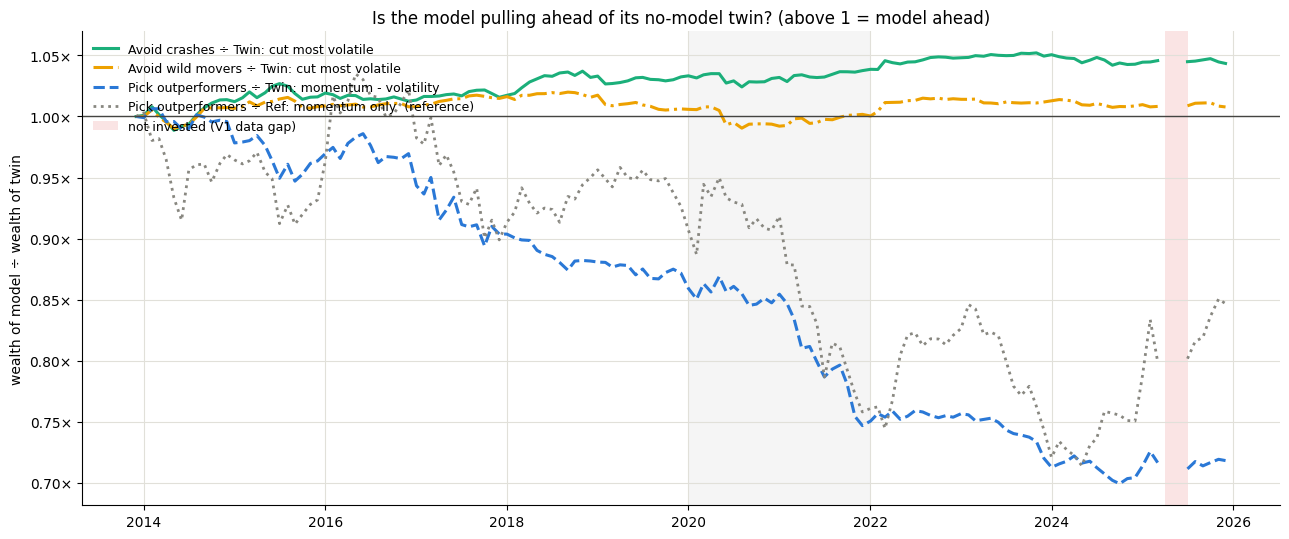

  [saved: 02_sharpe_diff_ci.png]


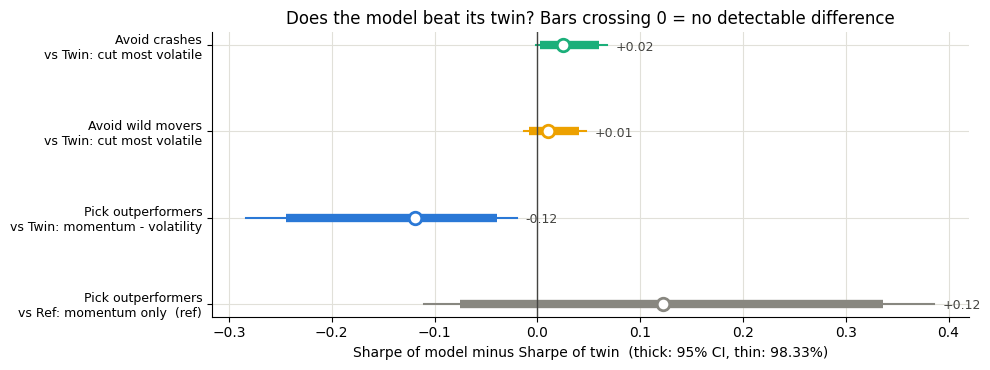

In [13]:
EXPORT_DIR = SANDBOX_DIR / "viz_exports_phase3b_twins"; EXPORT_DIR.mkdir(parents=True, exist_ok=True)
_n = {"k": 0}
def save_fig(fig, name):
    _n["k"] += 1; p = EXPORT_DIR / f"{_n['k']:02d}_{name}.png"
    fig.savefig(p, dpi=130, bbox_inches="tight"); print(f"  [saved: {p.name}]")
plt.rcParams.update({"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
                     "grid.color":"#e1e0d9","grid.linewidth":0.8})
from matplotlib.ticker import FuncFormatter
PSTY = {PAIRS[0]: dict(color="#1baf7a", ls="-", lw=2.2),
        PAIRS[1]: dict(color="#eda100", ls="-.", lw=2.2),
        PAIRS[2]: dict(color="#2a78d6", ls="--", lw=2.2),
        REF_PAIR: dict(color="#888780", ls=":", lw=2.0)}
idx = [R3.index[0] - pd.offsets.MonthBegin(1)] + list(R3.index)
GAP_X = [pd.Period(m, "M").start_time for m in SIT_OUT]
def with_breaks(values):
    s = pd.concat([pd.Series(values, index=idx), pd.Series(np.nan, index=GAP_X)]).sort_index()
    return s.index, s.to_numpy()

# 1. relative wealth: model / twin. Rising = model ahead; flat = no difference.
fig, ax = plt.subplots(figsize=(13, 5.5))
for (a, b), sty in PSTY.items():
    rel = wealth_curve(R3[a]) / wealth_curve(R3[b])
    lab = f"{a} ÷ {b}" + ("  (reference)" if (a, b) == REF_PAIR else "")
    ax.plot(*with_breaks(rel), label=lab, **sty)
ax.axhline(1, color="#444441", lw=1)
ax.axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31"), color="#888780", alpha=0.08, lw=0)
if SIT_OUT:
    ax.axvspan(pd.Period(SIT_OUT[0], "M").start_time, pd.Period(SIT_OUT[-1], "M").end_time,
               color="#e24b4a", alpha=0.15, lw=0, label="not invested (V1 data gap)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.2f}×"))
ax.set_ylabel("wealth of model ÷ wealth of twin")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("Is the model pulling ahead of its no-model twin? (above 1 = model ahead)")
fig.tight_layout(); save_fig(fig, "relative_wealth_model_vs_twin"); plt.show()

# 2. Sharpe-difference CIs: thick = 95%, thin = 98.33%
fig, ax = plt.subplots(figsize=(10, 3.8))
keys = PAIRS + [REF_PAIR]
for i, key in enumerate(keys):
    c = CIS[key]; y = len(keys) - 1 - i; col = PSTY[key]["color"]
    ax.plot([c["loB"], c["hiB"]], [y, y], color=col, lw=1.5)
    ax.plot([c["lo95"], c["hi95"]], [y, y], color=col, lw=6, solid_capstyle="butt")
    ax.plot(c["pt"], y, "o", color="white", mec=col, mew=2, ms=9, zorder=3)
    ax.annotate(f"{c['pt']:+.2f}", (c["hiB"], y), xytext=(6, -4), textcoords="offset points",
                fontsize=9, color="#444441")
ax.axvline(0, color="#444441", lw=1)
ax.set_yticks(range(len(keys)))
ax.set_yticklabels([f"{a}\nvs {b}" + ("  (ref)" if (a, b) == REF_PAIR else "") for a, b in keys][::-1], fontsize=9)
ax.set_xlabel("Sharpe of model minus Sharpe of twin  (thick: 95% CI, thin: 98.33%)")
ax.set_title("Does the model beat its twin? Bars crossing 0 = no detectable difference")
fig.tight_layout(); save_fig(fig, "sharpe_diff_ci"); plt.show()

## Cell 12 — Copy-paste summary

In [14]:
print("=" * 78); print("SAVED FIGURES:", EXPORT_DIR)
for p in sorted(EXPORT_DIR.glob("*.png")): print("   ", p.name)
print("=" * 78); print("COPY BELOW THIS LINE AND PASTE BACK"); print("=" * 78)
print(f"\n[setup] {len(R3)} invested months (sat out {SIT_OUT}); Phase 3a reproduced; twins checked")
print("\n[overlap, model vs twin]")
for k_, v in OVL.items(): print(f"  {k_:<52} mean {v.mean():.1%} min {v.min():.1%}")
print("\n[performance]")
print(T3[["cagr","vol","sharpe","max_dd","turnover","cost_yr_assumed","cagr_2014_19","cagr_2020_25"]]
      .to_string(float_format=lambda x: f"{x:+.3f}"))
print("\n[model minus twin: Sharpe diff]")
for key, c in CIS.items():
    tag = "REF" if key == REF_PAIR else VER[key]
    print(f"  {key[0]:<20} vs {key[1]:<28} {c['pt']:+.3f}  95% [{c['lo95']:+.3f}, {c['hi95']:+.3f}]  "
          f"98.33% [{c['loB']:+.3f}, {c['hiB']:+.3f}]  -> {tag}")
print("=" * 78)

SAVED FIGURES: /content/drive/MyDrive/moonshot_ml_sandbox/viz_exports_phase3b_twins
    01_relative_wealth_model_vs_twin.png
    02_sharpe_diff_ci.png
COPY BELOW THIS LINE AND PASTE BACK

[setup] 141 invested months (sat out ['2025-04', '2025-05', '2025-06']); Phase 3a reproduced; twins checked

[overlap, model vs twin]
  Avoid crashes | Twin: cut most volatile              mean 95.8% min 92.3%
  Avoid wild movers | Twin: cut most volatile          mean 96.9% min 93.2%
  Pick outperformers | Twin: momentum - volatility     mean 74.3% min 48.0%
  Pick outperformers | Ref: momentum only              mean 48.2% min 20.6%

[performance]
                              cagr    vol  sharpe  max_dd  turnover  cost_yr_assumed  cagr_2014_19  cagr_2020_25
portfolio                                                                                                       
Baseline                    +0.126 +0.213  +0.668  -0.454    +0.017           +0.001        +0.083        +0.173
Avoid crashes       